In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent))

from src.data_preparation import normalize_arabic

text = "إِنَّ الذَّكَاءَ الاصْطِنَاعِيَّ مُهِمٌّ"
print(normalize_arabic(text))

c:\Users\banda\OneDrive\سطح المكتب\MSIS822_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ان الذكاء الاصطناعي مهم


In [2]:
from src.data_preparation import load_texts

df, quality = load_texts()

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

Dataset shape: (41940, 5)

First five records:


,group_id,subset,source_model,label,text
0,by_polishing:0,by_polishing,human,0,كثيرا ما ارتبطت المصادر التاريخية في الأندلس خ...
1,by_polishing:0,by_polishing,allam,1,يتناول هذا البحث موضوع التعليم بين النساء الأن...
2,by_polishing:0,by_polishing,jais,1,تدرس هذه الدراسة دور المرأة في التعليم في الأن...
3,by_polishing:0,by_polishing,llama,1,يُقدم هذا البحث دراسة شاملة حول حالة التعليم ع...
4,by_polishing:0,by_polishing,openai,1,صور نظام التعليم عند المرأة الأندلسية تستند إل...


In [3]:
print("Data Quality Report")
display(quality)

print("\nClass Distribution")
print(df["label"].value_counts())

print("\nMissing Texts")
print(df["text"].isna().sum())

Data Quality Report


,subset,rows,duplicate_rows,missing,empty
0,by_polishing,2851,0,"{'original_abstract': 0, 'allam_generated_abst...","{'original_abstract': 0, 'allam_generated_abst..."
1,from_title,2963,0,"{'original_abstract': 0, 'allam_generated_abst...","{'original_abstract': 0, 'allam_generated_abst..."
2,from_title_and_content,2574,0,"{'original_abstract': 0, 'allam_generated_abst...","{'original_abstract': 0, 'allam_generated_abst..."



Class Distribution
label
1    33552
0     8388
Name: count, dtype: int64

Missing Texts
0


In [4]:
from src.data_preparation import preprocess_dataframe

sample = df.head(5).copy()
processed_sample = preprocess_dataframe(sample)

display(
    processed_sample[
        ["source_model", "text", "normalized_text", "processed_text"]
    ]
)

,source_model,text,normalized_text,processed_text
0,human,كثيرا ما ارتبطت المصادر التاريخية في الأندلس خ...,كثيرا ما ارتبطت المصادر التاريخية في الاندلس خ...,ربط صدر ارخ دلس كتب رجم هرس رمج وغر درس حية عل...
1,allam,يتناول هذا البحث موضوع التعليم بين النساء الأن...,يتناول هذا البحث موضوع التعليم بين النساء الان...,نول بحث وضع علم نسء دلس خلل درس صدر ارخ تعلق ر...
2,jais,تدرس هذه الدراسة دور المرأة في التعليم في الأن...,تدرس هذه الدراسة دور المراة في التعليم في الان...,درس درس دور راة علم دلس خلل صدر ارخ كتب رجم هر...
3,llama,يُقدم هذا البحث دراسة شاملة حول حالة التعليم ع...,يقدم هذا البحث دراسة شاملة حول حالة التعليم عن...,قدم بحث درس شمل حول حلة علم راة دلس خلل عصر وس...
4,openai,صور نظام التعليم عند المرأة الأندلسية تستند إل...,صور نظام التعليم عند المراة الاندلسية تستند ال...,صور نظم علم راة دلس سند درس دقق صدر ارخ وثق حي...


In [6]:
import pandas as pd

features = pd.read_csv("../data/processed/text_statistics.csv")

print("Average Text Features by Class")

display(
    features.groupby("label")[
        ["word_count", "avg_word_length",
         "type_token_ratio", "function_word_ratio"]
    ].mean().round(2)
)

Average Text Features by Class


,word_count,avg_word_length,type_token_ratio,function_word_ratio
label,,,,
0,121.46,4.98,0.79,0.16
1,102.57,5.26,0.76,0.16


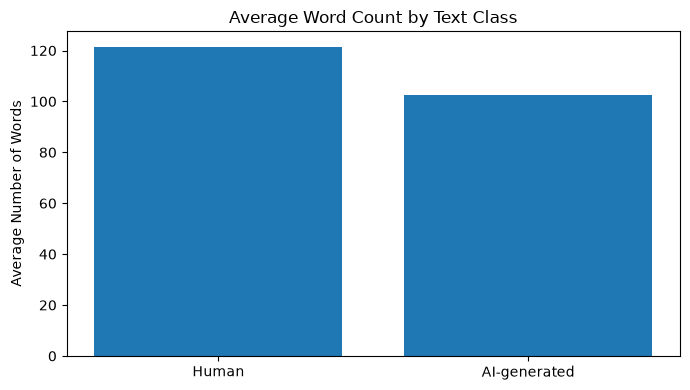

In [7]:
import matplotlib.pyplot as plt

avg_words = features.groupby("label")["word_count"].mean()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Human", "AI-generated"],
    [avg_words.loc[0], avg_words.loc[1]]
)

plt.title("Average Word Count by Text Class")
plt.ylabel("Average Number of Words")
plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path
from IPython.display import Image, display

figures_dir = Path.cwd().parent / "reports" / "figures"

for file in sorted(figures_dir.glob("wordcloud*.png")):
    print(file.name)
    display(Image(filename=str(file)))

Word Cloud: HUMAN


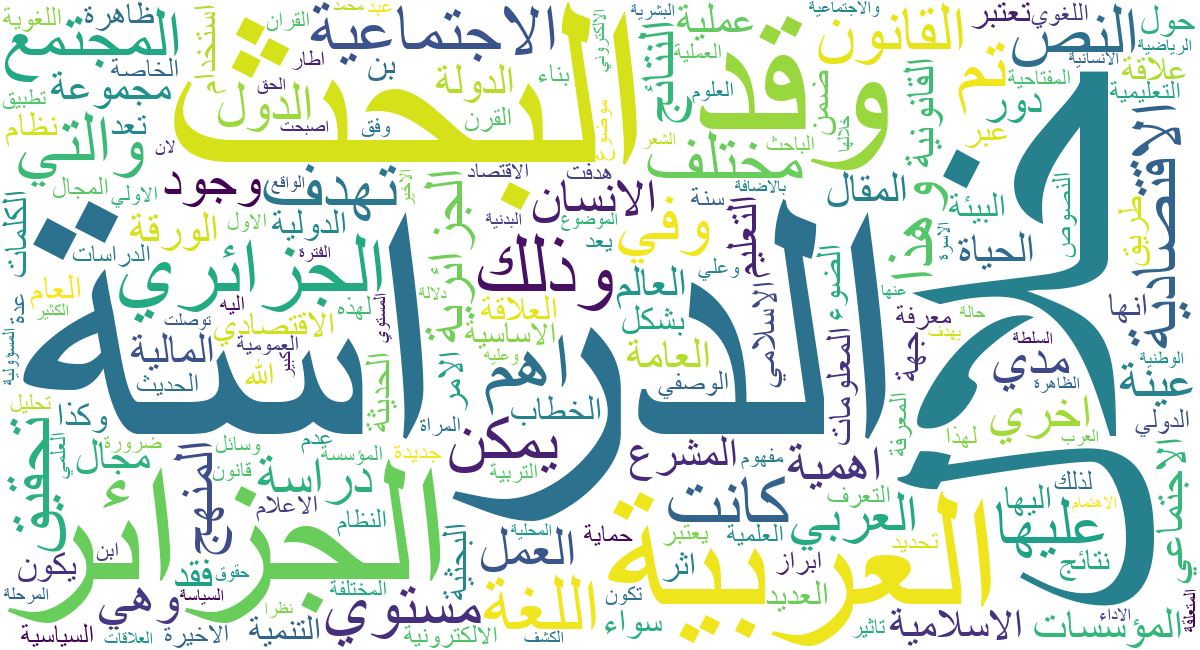

Word Cloud: AI


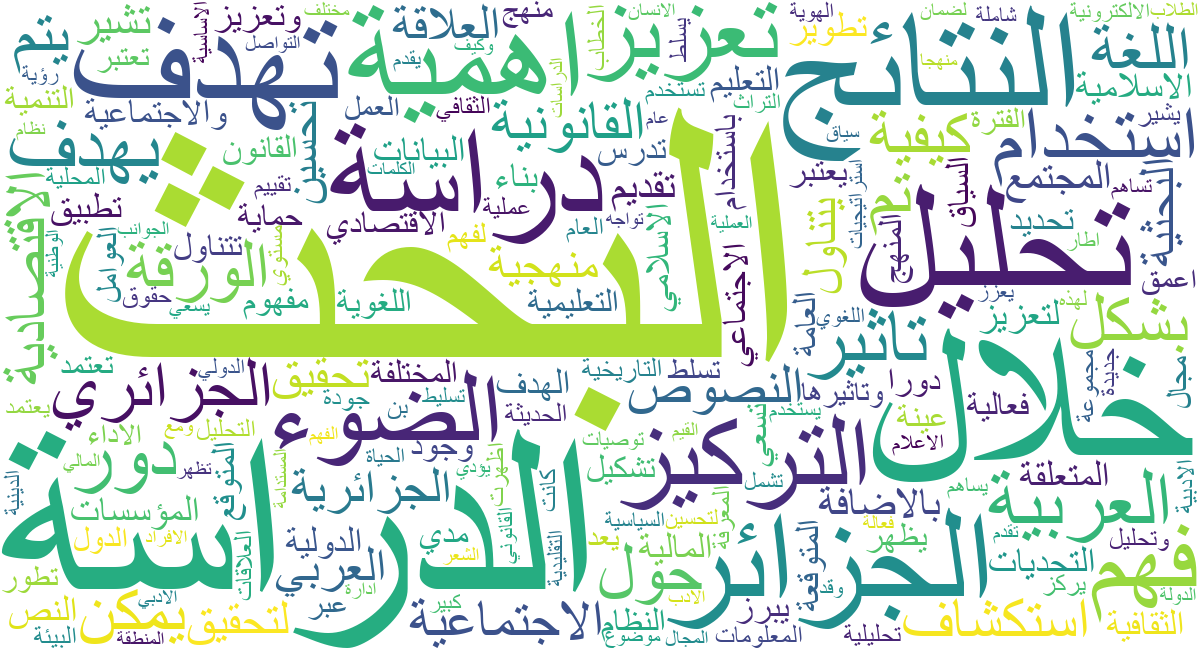

In [1]:

from pathlib import Path
from IPython.display import display, Image

figures_dir = Path.cwd().parent / "reports" / "figures"

for name in ["human", "ai"]:
    file = figures_dir / f"wordcloud_{name}.png"

    if file.exists():
        print(f"Word Cloud: {name.upper()}")
        display(Image(filename=str(file)))
    else:
        print(f"Image not found: {file}")



## Phase 2 – Exploratory Data Analysis Findings

The dataset contains 8,388 human-written texts and 33,552 AI-generated texts.

### Linguistic Statistics

Human-written texts contain approximately 118.58 words on average, compared with 101.01 words in AI-generated texts.

AI-generated texts have a slightly higher average word length (5.33 versus 5.08 characters).

The type-token ratio is slightly higher for human-written texts (0.792) than for AI-generated texts (0.767). However, this measure can be affected by text length.

The average sentence length is higher in human-written texts, but this result depends on punctuation-based sentence splitting.

### Word Clouds

Word clouds were generated for both human-written and AI-generated texts after Arabic normalization and stopword removal, without stemming.

Both groups share many frequent words, including terms related to research, education, and society.

### Initial Interpretation

The results show some differences in writing characteristics between human and AI-generated Arabic texts. However, these descriptive statistics alone are not sufficient to determine whether a text was written by a human or generated by AI.

### N-gram Analysis

I analyzed the most frequent one-word, two-word, and three-word expressions in human-written and AI-generated Arabic abstracts.

The human-written texts included phrases related to research methods and specific topics, such as "المنهج الوصفي التحليلي" and "التربية البدنية والرياضية".

The AI-generated texts frequently used expressions related to research objectives, such as "تهدف الدراسة استكشاف" and "يهدف البحث دراسة".

These results suggest some differences in the commonly used expressions between the two groups. However, the AI-generated class contains four times as many texts as the human-written class, so raw frequencies alone are not sufficient to determine which expressions are more characteristic of either group.
